# Method 11 (Pilot - Small Dataset): Residual Concat (512->256) + Objective Standard VFL

**Cải tiến so với Method 10:**
1. **Residual Concat Fusion (`page_feat + delta(cat([page_feat, book_ctx]))`)**: Ghép kênh thành 512 chiều rồi trộn có chọn lọc và cộng residual (khởi tạo `delta=0` để giữ 100% trọng số pretrained RT-DETRv2).
2. **Objective mAP-Aligned Loss**: Dùng `RTDetrLoss` chuẩn (VFL đồng đều `1.0` cho cả 11 lớp), không ép trọng số lệch 4.5x.
3. **Tái sử dụng Book Context Cache từ Method 10** (`C:/doclaynet_cache/method10/pilot_book_ctx_*.npy`).
4. **Book-Grouped Batching + Photometric Augmentation + Context Dropout (0.1)**.


In [1]:
import os
import sys
import json
import time
import random
import shutil
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

REPO_ROOT = Path(r"d:\Semester_261\DoAnChuyenNganh\DO-AN-261")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from methods.method11.common import (
    TRAIN_ANNO, VAL_ANNO,
    TRAIN_IMG_640, VAL_IMG_640,
    TRAIN_IMG_SRC, VAL_IMG_SRC,
    CACHE_DIR, WEIGHTS_DIR, REPORT_DIR,
    CATEGORIES, load_coco, book_of,
)
from methods.method11.models.rtdetr_method11 import ResidualConcatRTDetrMethod11
from methods.method11.dataset import (
    precompute_backbone_book_context,
    Method11FastDataset,
    BookGroupedBatchSampler,
    collate_fn_m11,
    evaluate_method11_coco_map,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"Total VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

c_free_gb = shutil.disk_usage("C:/").free / 1e9
print(f"C:/ free space: {c_free_gb:.2f} GB | Shared CACHE_DIR: {CACHE_DIR}")

BATCH_SIZE = 8
GRAD_ACCUM = 1
EPOCHS = 3
LR = 5e-5
FUSION_LR = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0  # Pilot chạy nhanh không cần spawn worker


KeyboardInterrupt: 

In [ ]:
def make_subset_coco(coco_dict: dict, selected_books: set) -> dict:
    imgs = [img for img in coco_dict["images"] if book_of(img) in selected_books]
    img_ids = {img["id"] for img in imgs}
    anns = [ann for ann in coco_dict["annotations"] if ann["image_id"] in img_ids]
    return {
        "images": imgs,
        "annotations": anns,
        "categories": coco_dict.get("categories", CATEGORIES),
    }

def pick_books_with_page_range(coco_dict: dict, n_books: int, min_pages: int = 4, max_pages: int = 12, seed: int = 42) -> set:
    by_book = defaultdict(list)
    for img in coco_dict["images"]:
        by_book[book_of(img)].append(img)
    eligible = sorted([b for b, ims in by_book.items() if min_pages <= len(ims) <= max_pages])
    rng = random.Random(seed)
    rng.shuffle(eligible)
    return set(eligible[:n_books])

print("Loading COCO annotations...")
full_train_coco = load_coco(TRAIN_ANNO)
full_val_coco = load_coco(VAL_ANNO)

pilot_train_books = pick_books_with_page_range(full_train_coco, n_books=25, min_pages=4, max_pages=12, seed=SEED)
pilot_val_books = pick_books_with_page_range(full_val_coco, n_books=8, min_pages=4, max_pages=15, seed=SEED + 1)
assert len(pilot_train_books & pilot_val_books) == 0, "Book leakage detected!"

pilot_train_coco = make_subset_coco(full_train_coco, pilot_train_books)
pilot_val_coco = make_subset_coco(full_val_coco, pilot_val_books)

print(f"Pilot Train: {len(pilot_train_books)} books, {len(pilot_train_coco['images'])} pages, {len(pilot_train_coco['annotations'])} boxes")
print(f"Pilot Val:   {len(pilot_val_books)} books, {len(pilot_val_coco['images'])} pages, {len(pilot_val_coco['annotations'])} boxes")


Loading COCO annotations...
Pilot Train: 25 books, 174 pages, 3577 boxes
Pilot Val:   8 books, 80 pages, 1113 boxes


In [ ]:
model = ResidualConcatRTDetrMethod11(ctx_dropout=0.1).to(device)

bb_trainable = sum(p.numel() for p in model.rtdetr.model.backbone.parameters() if p.requires_grad)
ctx_proj_trainable = sum(p.numel() for p in model.frozen_ctx_proj.parameters() if p.requires_grad)
fusion_trainable = sum(p.numel() for p in model.fusion_block.parameters() if p.requires_grad)
total_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())

print(f"Frozen backbone trainable params:        {bb_trainable:,} (expected 0)")
print(f"Frozen ctx proj trainable params:        {ctx_proj_trainable:,} (expected 0)")
print(f"Trainable ResidualConcatFusion params:   {fusion_trainable:,}")
print(f"Total trainable / Total params:          {total_trainable:,} / {total_params:,} ({100*total_trainable/total_params:.2f}%)")
assert bb_trainable == 0 and ctx_proj_trainable == 0


[Method11] Nạp pretrained RT-DETRv2 từ: docling-project/docling-layout-heron
[Method11] Backbone đóng băng | Fusion: Residual Concat (512->256) | Loss: Objective Standard VFL.
Frozen backbone trainable params:        0 (expected 0)
Frozen ctx proj trainable params:        0 (expected 0)
Trainable ResidualConcatFusion params:   2,362,368
Total trainable / Total params:          21,650,259 / 46,043,315 (47.02%)


In [ ]:
train_mmap_path, train_book_idx = precompute_backbone_book_context(
    images_list=pilot_train_coco["images"],
    img_640_dir=TRAIN_IMG_640,
    img_raw_dir=TRAIN_IMG_SRC,
    model=model,
    split="train",
    batch_size=16,
    prefix="pilot_",
    device=device,
)

val_mmap_path, val_book_idx = precompute_backbone_book_context(
    images_list=pilot_val_coco["images"],
    img_640_dir=VAL_IMG_640,
    img_raw_dir=VAL_IMG_SRC,
    model=model,
    split="val",
    batch_size=16,
    prefix="pilot_",
    device=device,
)

train_ds = Method11FastDataset(pilot_train_coco, TRAIN_IMG_640, TRAIN_IMG_SRC, train_mmap_path, train_book_idx, augment=True)
val_ds = Method11FastDataset(pilot_val_coco, VAL_IMG_640, VAL_IMG_SRC, val_mmap_path, val_book_idx, augment=False)

train_batch_sampler = BookGroupedBatchSampler(train_ds, batch_size=BATCH_SIZE, seed=SEED)
train_loader = DataLoader(
    train_ds, batch_sampler=train_batch_sampler,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"), collate_fn=collate_fn_m11,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"), collate_fn=collate_fn_m11,
)
print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)}")


[Method11 Cache] Reused existing train book context cache: 25 books -> C:\doclaynet_cache\method10\pilot_book_ctx_train.npy
[Method11 Cache] Reused existing val book context cache: 8 books -> C:\doclaynet_cache\method10\pilot_book_ctx_val.npy
Train batches: 22 | Val batches: 10


In [ ]:
print("Evaluating Epoch 0 (Before Fine-Tuning - verifying 100% pretrained preservation)...")
ep0_metrics = evaluate_method11_coco_map(model, val_loader, pilot_val_coco, device, desc="Pilot Val Ep0")
print(f"Epoch 0 | mAP@[.50:.95]: {ep0_metrics['mAP']:.4f} | AP50: {ep0_metrics['AP50']:.4f} | AP75: {ep0_metrics['AP75']:.4f}")

trainable_params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(model.get_param_groups(lr=LR, fusion_lr=FUSION_LR, weight_decay=WEIGHT_DECAY))
total_steps = max(1, (len(train_loader) // GRAD_ACCUM) * EPOCHS)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_steps, eta_min=LR * 0.1)


Evaluating Epoch 0 (Before Fine-Tuning - verifying 100% pretrained preservation)...
Epoch 0 | mAP@[.50:.95]: 0.7814 | AP50: 0.9229 | AP75: 0.8542


In [ ]:
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

history = []
best_map = -1.0
best_ckpt = WEIGHTS_DIR / "best_pilot_method11.pt"

for epoch in range(1, EPOCHS + 1):
    t_ep = time.time()
    train_batch_sampler.set_epoch(epoch)
    model.train()
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    optimizer.zero_grad(set_to_none=True)
    loss_acc = {"loss": 0.0, "loss_vfl": 0.0, "loss_bbox": 0.0, "loss_giou": 0.0}
    n_batches = 0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [Train]", leave=True)
    for step, (pixs, book_means, book_counts, labels) in enumerate(pbar, start=1):
        pixs = pixs.to(device, non_blocking=True)
        book_means = [m.to(device, non_blocking=True) for m in book_means]
        book_counts = book_counts.to(device, non_blocking=True)
        labels_dev = [
            {
                "boxes": lb["boxes"].to(device, non_blocking=True),
                "class_labels": lb["class_labels"].to(device, non_blocking=True),
            }
            for lb in labels
        ]

        with torch.amp.autocast("cuda", dtype=torch.bfloat16, enabled=(device.type == "cuda")):
            out = model(pixs, book_means, book_counts, labels=labels_dev)
            loss = out["loss"] / GRAD_ACCUM

        loss.backward()

        if step % GRAD_ACCUM == 0 or step == len(train_loader):
            torch.nn.utils.clip_grad_norm_(trainable_params, max_norm=1.0)
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()

        ld = out["loss_dict"]
        loss_acc["loss"] += float(out["loss"].detach().item())
        loss_acc["loss_vfl"] += float(ld.get("loss_vfl", 0.0))
        loss_acc["loss_bbox"] += float(ld.get("loss_bbox", 0.0))
        loss_acc["loss_giou"] += float(ld.get("loss_giou", 0.0))
        n_batches += 1

    val_metrics = evaluate_method11_coco_map(model, val_loader, pilot_val_coco, device, desc=f"Epoch {epoch} [Val]")
    delta_ratios = [round(float(r), 5) for r in model.fusion_block.last_delta_ratios]
    peak_vram = torch.cuda.max_memory_allocated() / 1e9 if device.type == "cuda" else 0.0
    ep_time = time.time() - t_ep

    row = {
        "epoch": epoch,
        "train_loss": loss_acc["loss"] / max(n_batches, 1),
        "loss_vfl": loss_acc["loss_vfl"] / max(n_batches, 1),
        "loss_bbox": loss_acc["loss_bbox"] / max(n_batches, 1),
        "loss_giou": loss_acc["loss_giou"] / max(n_batches, 1),
        "val_mAP": val_metrics["mAP"],
        "val_AP50": val_metrics["AP50"],
        "val_AP75": val_metrics["AP75"],
        "per_class": val_metrics["per_class"],
        "delta_ratios": delta_ratios,
        "lr": optimizer.param_groups[0]["lr"],
        "peak_vram_gb": round(peak_vram, 2),
        "epoch_time_sec": round(ep_time, 1),
    }
    history.append(row)

    print(
        f"Epoch {epoch}/{EPOCHS} | Loss: {row['train_loss']:.4f} "
        f"(VFL={row['loss_vfl']:.4f}, Bbox={row['loss_bbox']:.4f}, GIoU={row['loss_giou']:.4f}) | "
        f"Val mAP: {row['val_mAP']:.4f} | AP50: {row['val_AP50']:.4f} | AP75: {row['val_AP75']:.4f} | "
        f"DeltaRatio: {delta_ratios} | VRAM: {peak_vram:.2f} GB | Time: {ep_time:.1f}s"
    )

    if val_metrics["mAP"] > best_map:
        best_map = val_metrics["mAP"]
        torch.save({"epoch": epoch, "model_state_dict": model.state_dict(), "val_metrics": val_metrics}, best_ckpt)
        print(f"  -> Saved new best pilot checkpoint (mAP={best_map:.4f})")

with open(REPORT_DIR / "pilot_history.json", "w", encoding="utf-8") as f:
    json.dump({"epoch0": ep0_metrics, "history": history}, f, indent=2)


Epoch 1/3 | Loss: 8.9950 (VFL=0.3854, Bbox=0.0330, GIoU=0.1659) | Val mAP: 0.7862 | AP50: 0.9200 | AP75: 0.8425 | DeltaRatio: [0.01414, 0.01394, 0.03228] | VRAM: 3.92 GB | Time: 21.7s
  -> Saved new best pilot checkpoint (mAP=0.7862)
Epoch 2/3 | Loss: 7.9623 (VFL=0.3267, Bbox=0.0289, GIoU=0.1466) | Val mAP: 0.7854 | AP50: 0.9176 | AP75: 0.8469 | DeltaRatio: [0.0197, 0.02118, 0.03922] | VRAM: 3.92 GB | Time: 19.7s
Epoch 3/3 | Loss: 7.6536 (VFL=0.3146, Bbox=0.0286, GIoU=0.1450) | Val mAP: 0.7899 | AP50: 0.9190 | AP75: 0.8514 | DeltaRatio: [0.02182, 0.02309, 0.0415] | VRAM: 3.92 GB | Time: 18.9s
  -> Saved new best pilot checkpoint (mAP=0.7899)



Best Pilot Val Epoch 3 | mAP=0.7899
  Caption           : 0.9339
  Footnote          : 0.6991
  Formula           : 0.7920
  List-item         : 0.9239
  Page-footer       : 0.7674
  Page-header       : 0.8638
  Picture           : 0.9587
  Section-header    : 0.6602
  Table             : 0.9136
  Text              : 0.9100
  Title             : 0.2665


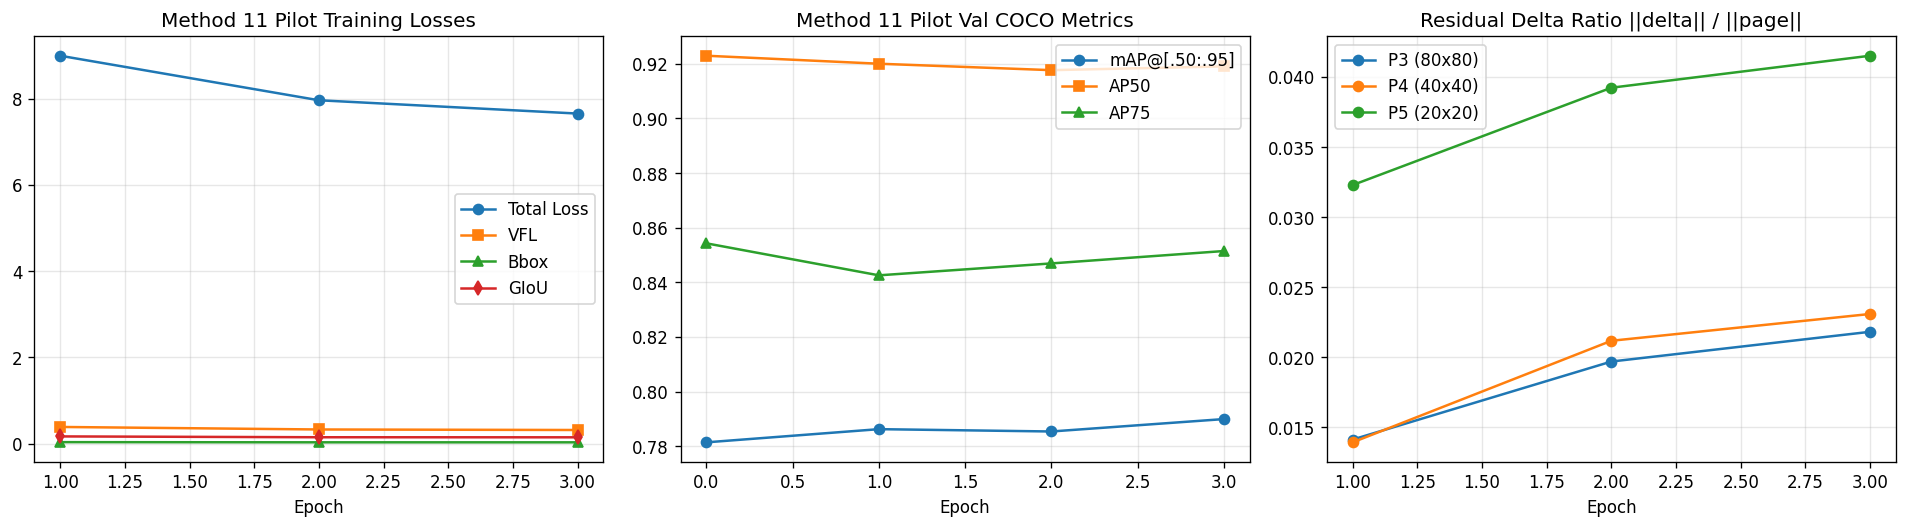

In [ ]:
epochs_x = [0] + [h["epoch"] for h in history]
maps_y = [ep0_metrics["mAP"]] + [h["val_mAP"] for h in history]
ap50_y = [ep0_metrics["AP50"]] + [h["val_AP50"] for h in history]
ap75_y = [ep0_metrics["AP75"]] + [h["val_AP75"] for h in history]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot([h["epoch"] for h in history], [h["train_loss"] for h in history], marker="o", label="Total Loss")
axes[0].plot([h["epoch"] for h in history], [h["loss_vfl"] for h in history], marker="s", label="VFL")
axes[0].plot([h["epoch"] for h in history], [h["loss_bbox"] for h in history], marker="^", label="Bbox")
axes[0].plot([h["epoch"] for h in history], [h["loss_giou"] for h in history], marker="d", label="GIoU")
axes[0].set_title("Method 11 Pilot Training Losses")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_x, maps_y, marker="o", label="mAP@[.50:.95]")
axes[1].plot(epochs_x, ap50_y, marker="s", label="AP50")
axes[1].plot(epochs_x, ap75_y, marker="^", label="AP75")
axes[1].set_title("Method 11 Pilot Val COCO Metrics")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

for s_idx, s_name in enumerate(["P3 (80x80)", "P4 (40x40)", "P5 (20x20)"]):
    axes[2].plot([h["epoch"] for h in history], [h["delta_ratios"][s_idx] for h in history], marker="o", label=s_name)
axes[2].set_title("Residual Delta Ratio ||delta|| / ||page||")
axes[2].set_xlabel("Epoch")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

best_row = max(history, key=lambda r: r["val_mAP"])
print(f"\nBest Pilot Val Epoch {best_row['epoch']} | mAP={best_row['val_mAP']:.4f}")
for cls_name, ap in best_row["per_class"].items():
    print(f"  {cls_name:<18}: {ap:.4f}")
